In [4]:
import torch

# Check if GPU is available
gpu_available = torch.cuda.is_available()
print("CUDA available:", gpu_available)

if gpu_available:
    print("Number of GPUs:", torch.cuda.device_count())
    for i in range(torch.cuda.device_count()):
        print(f"Device {i}: {torch.cuda.get_device_name(i)}")
    # Check current device
    print("Current device:", torch.cuda.current_device())
else:
    print("No GPU detected, using CPU instead.")

# Optional: check if PyTorch can allocate a small tensor on GPU
try:
    x = torch.tensor([1.0], device="cuda")
    print("Successfully allocated tensor on GPU:", x)
except Exception as e:
    print("GPU test failed:", e)


CUDA available: True
Number of GPUs: 2
Device 0: Tesla T4
Device 1: Tesla T4
Current device: 0
Successfully allocated tensor on GPU: tensor([1.], device='cuda:0')


In [5]:
import os
print(os.listdir("/kaggle/input"))


['lgg-mri-segmentation']


In [6]:
import os

# Set base path to your dataset
base_path = "/kaggle/input/lgg-mri-segmentation"

# List all files and folders in the dataset
print(os.listdir(base_path))


['kaggle_3m', 'lgg-mri-segmentation']


In [7]:
import os

# Correct main dataset path
base_path = "/kaggle/input/lgg-mri-segmentation"
root_dir = os.path.join(base_path, "kaggle_3m")   # where all patient subfolders exist
output_dir = "/kaggle/working/data"               # writable directory for processed data

# Create directories
os.makedirs(output_dir, exist_ok=True)

print("Base folder contents:", os.listdir(base_path))
print("First few patient folders inside kaggle_3m:")
print(os.listdir(root_dir)[:5])

Base folder contents: ['kaggle_3m', 'lgg-mri-segmentation']
First few patient folders inside kaggle_3m:
['TCGA_DU_7010_19860307', 'TCGA_DU_8162_19961029', 'TCGA_FG_A4MT_20020212', 'TCGA_FG_5964_20010511', 'TCGA_DU_A5TS_19970726']


In [8]:
import os

sample_patient = os.path.join(root_dir, "TCGA_DU_7010_19860307")  # any one folder
print("Files inside sample patient folder:")
print(os.listdir(sample_patient)[:10])


Files inside sample patient folder:
['TCGA_DU_7010_19860307_45.tif', 'TCGA_DU_7010_19860307_56_mask.tif', 'TCGA_DU_7010_19860307_57.tif', 'TCGA_DU_7010_19860307_33.tif', 'TCGA_DU_7010_19860307_27.tif', 'TCGA_DU_7010_19860307_52.tif', 'TCGA_DU_7010_19860307_10.tif', 'TCGA_DU_7010_19860307_8_mask.tif', 'TCGA_DU_7010_19860307_34_mask.tif', 'TCGA_DU_7010_19860307_33_mask.tif']


In [9]:
import os, shutil

# Define paths
root_dir = "/kaggle/input/lgg-mri-segmentation/kaggle_3m"
output_dir = "/kaggle/working/data"
images_dir = os.path.join(output_dir, "images")
masks_dir = os.path.join(output_dir, "masks")

# Create output directories
os.makedirs(images_dir, exist_ok=True)
os.makedirs(masks_dir, exist_ok=True)

# Copy all files
img_count, mask_count = 0, 0

for patient in os.listdir(root_dir):
    p_path = os.path.join(root_dir, patient)
    if not os.path.isdir(p_path):
        continue

    for f in os.listdir(p_path):
        if f.endswith(".tif"):
            src = os.path.join(p_path, f)
            if "_mask" in f:
                shutil.copy(src, os.path.join(masks_dir, f))
                mask_count += 1
            else:
                shutil.copy(src, os.path.join(images_dir, f))
                img_count += 1

print(f"Copied {img_count} images and {mask_count} masks successfully.")


Copied 3929 images and 3929 masks successfully.


In [10]:
image_files = sorted(os.listdir(images_dir))
mask_files = sorted(os.listdir(masks_dir))

aligned_images, aligned_masks = [], []

for img_file in image_files:
    base = img_file.replace(".tif", "")
    mask_name = base + "_mask.tif"
    if mask_name in mask_files:
        aligned_images.append(img_file)
        aligned_masks.append(mask_name)

print(f"Total perfectly aligned images: {len(aligned_images)}")
print(f"Total perfectly aligned masks: {len(aligned_masks)}")
print("\n Sample pairs:")
for i in range(5):
    print(f"{aligned_images[i]}  <-->  {aligned_masks[i]}")


Total perfectly aligned images: 3929
Total perfectly aligned masks: 3929

 Sample pairs:
TCGA_CS_4941_19960909_1.tif  <-->  TCGA_CS_4941_19960909_1_mask.tif
TCGA_CS_4941_19960909_10.tif  <-->  TCGA_CS_4941_19960909_10_mask.tif
TCGA_CS_4941_19960909_11.tif  <-->  TCGA_CS_4941_19960909_11_mask.tif
TCGA_CS_4941_19960909_12.tif  <-->  TCGA_CS_4941_19960909_12_mask.tif
TCGA_CS_4941_19960909_13.tif  <-->  TCGA_CS_4941_19960909_13_mask.tif


In [11]:
import cv2
import numpy as np

IMG_SIZE = 256  # Resize images for faster training, can adjust

def load_data(image_list, mask_list, img_dir, mask_dir):
    images, masks = [], []
    for img_file, mask_file in zip(image_list, mask_list):
        img_path = os.path.join(img_dir, img_file)
        mask_path = os.path.join(mask_dir, mask_file)
        
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # or cv2.IMREAD_COLOR if needed
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
        
        # Normalize images and masks
        img = img / 255.0
        mask = mask / 255.0
        mask = np.expand_dims(mask, axis=-1)  # Needed for PyTorch/CNN
        
        images.append(img)
        masks.append(mask)
    
    images = np.array(images, dtype=np.float32)
    masks = np.array(masks, dtype=np.float32)
    
    return images, masks

X, Y = load_data(aligned_images, aligned_masks, images_dir, masks_dir)
print(f"Images shape: {X.shape}, Masks shape: {Y.shape}")


Images shape: (3929, 256, 256), Masks shape: (3929, 256, 256, 1)


In [12]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

X_tensor = torch.tensor(X).unsqueeze(1).to(device)  # (N,H,W) -> (N,1,H,W)
if Y.ndim == 3:  # shape (N,H,W)
    Y = np.expand_dims(Y, axis=-1)

Y_tensor = torch.tensor(Y).permute(0,3,1,2).to(device)

print("Tensors ready on device:", device)
print("X shape:", X_tensor.shape)
print("Y shape:", Y_tensor.shape)


Tensors ready on device: cuda
X shape: torch.Size([3929, 1, 256, 256])
Y shape: torch.Size([3929, 1, 256, 256])


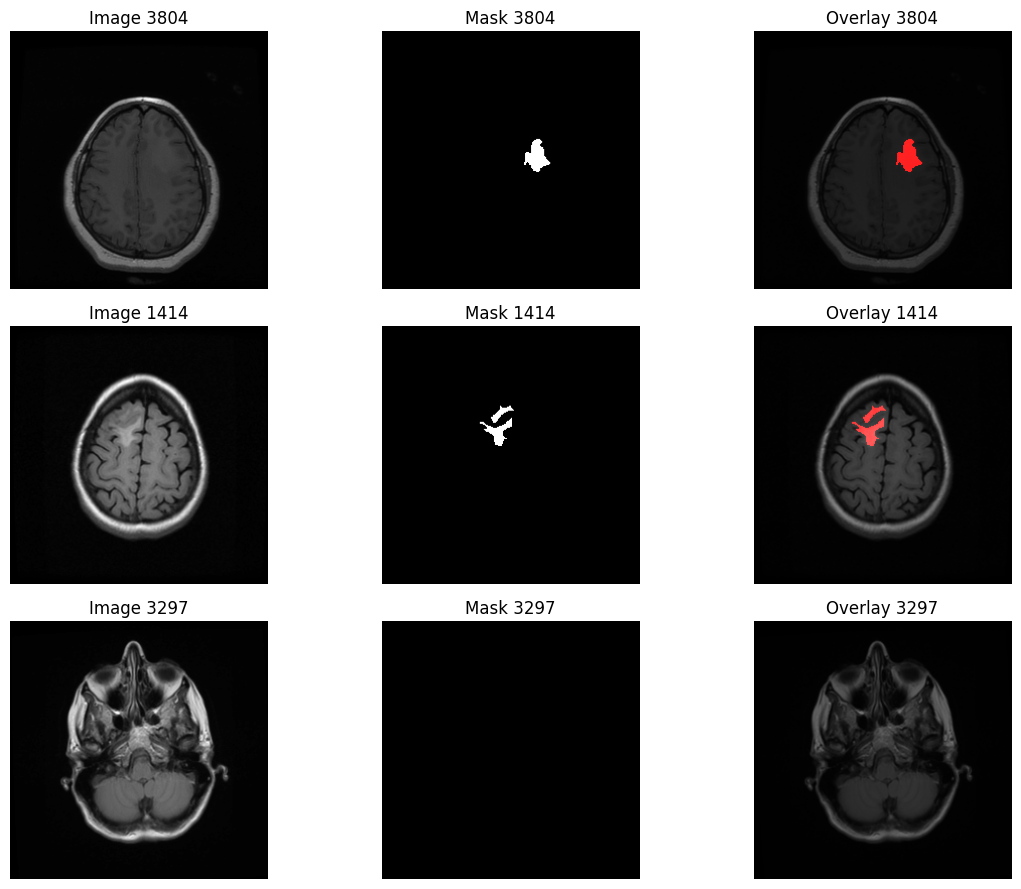

In [16]:
import matplotlib.pyplot as plt
import random

num_samples = 3  # Number of samples to display
indices = random.sample(range(len(X_tensor)), num_samples)

plt.figure(figsize=(12, num_samples*3))

for i, idx in enumerate(indices):
    img = X_tensor[idx].squeeze().cpu().numpy()  # (H,W)
    mask = Y_tensor[idx].squeeze().cpu().numpy() # (H,W)
    
    # Overlay
    overlay = np.stack([img, img, img], axis=-1)  # Convert to RGB
    overlay[..., 0] = np.maximum(overlay[..., 0], mask)  # Red channel for mask
    
    # Original image
    plt.subplot(num_samples, 3, i*3+1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Image {idx}")
    plt.axis('off')
    
    # Mask alone
    plt.subplot(num_samples, 3, i*3+2)
    plt.imshow(mask, cmap='gray')
    plt.title(f"Mask {idx}")
    plt.axis('off')
    
    # Image + mask overlay
    plt.subplot(num_samples, 3, i*3+3)
    plt.imshow(overlay)
    plt.title(f"Overlay {idx}")
    plt.axis('off')

plt.tight_layout()
plt.show()



In [14]:
import os

IMG_DIR = "/kaggle/working/data/images"
MASK_DIR = "/kaggle/working/data/masks"

image_files = set(os.listdir(IMG_DIR))
mask_files = set(os.listdir(MASK_DIR))

# remove extensions before comparing (common issue)
img_basenames = {os.path.splitext(f)[0] for f in image_files}
mask_basenames = {os.path.splitext(f)[0] for f in mask_files}

missing_masks = img_basenames - mask_basenames
missing_images = mask_basenames - img_basenames

print(f"Total images: {len(image_files)}")
print(f"Total masks: {len(mask_files)}")
print(f"Images missing masks: {len(missing_masks)}")
print(f"Masks missing images: {len(missing_images)}")

if len(missing_masks) > 0:
    print("Examples missing masks:", list(missing_masks)[:5])
if len(missing_images) > 0:
    print("Examples missing images:", list(missing_images)[:5])


Total images: 3929
Total masks: 3929
Images missing masks: 3929
Masks missing images: 3929
Examples missing masks: ['TCGA_DU_A5TT_19980318_41', 'TCGA_DU_6404_19850629_5', 'TCGA_CS_6188_20010812_6', 'TCGA_DU_6399_19830416_26', 'TCGA_DU_7299_19910417_8']
Examples missing images: ['TCGA_CS_5397_20010315_10_mask', 'TCGA_DU_8162_19961029_7_mask', 'TCGA_DU_7301_19911112_33_mask', 'TCGA_FG_A4MT_20020212_32_mask', 'TCGA_HT_7882_19970125_21_mask']


In [15]:
import os

IMG_DIR = "/kaggle/working/data/images"
MASK_DIR = "/kaggle/working/data/masks"

image_files = os.listdir(IMG_DIR)
mask_files = os.listdir(MASK_DIR)

# remove extension + "_mask" for matching
img_basenames = {os.path.splitext(f)[0] for f in image_files}
mask_basenames = {os.path.splitext(f)[0].replace("_mask", "") for f in mask_files}

missing_masks = img_basenames - mask_basenames
missing_images = mask_basenames - img_basenames

print(f"Total images: {len(image_files)}")
print(f"Total masks: {len(mask_files)}")
print(f"Images missing masks: {len(missing_masks)}")
print(f"Masks missing images: {len(missing_images)}")

if len(missing_masks) > 0:
    print("Examples missing masks:", list(missing_masks)[:5])
if len(missing_images) > 0:
    print("Examples missing images:", list(missing_images)[:5])


Total images: 3929
Total masks: 3929
Images missing masks: 0
Masks missing images: 0


In [17]:
import os
import pandas as pd

IMG_DIR = "/kaggle/working/data/images"
MASK_DIR = "/kaggle/working/data/masks"

# create list of tuples (image_path, mask_path)
pairs = []
for img_name in os.listdir(IMG_DIR):
    base = os.path.splitext(img_name)[0]
    mask_name = base + "_mask.tif"
    mask_path = os.path.join(MASK_DIR, mask_name)
    if os.path.exists(mask_path):
        pairs.append((os.path.join(IMG_DIR, img_name), mask_path))

print(f"Total valid pairs found: {len(pairs)}")

# store in DataFrame for clarity
df = pd.DataFrame(pairs, columns=["image_path", "mask_path"])
df.head()


Total valid pairs found: 3929


,image_path,mask_path
0,/kaggle/working/data/images/TCGA_DU_5874_19950...,/kaggle/working/data/masks/TCGA_DU_5874_199505...
1,/kaggle/working/data/images/TCGA_CS_6188_20010...,/kaggle/working/data/masks/TCGA_CS_6188_200108...
2,/kaggle/working/data/images/TCGA_DU_5874_19950...,/kaggle/working/data/masks/TCGA_DU_5874_199505...
3,/kaggle/working/data/images/TCGA_HT_A61B_19991...,/kaggle/working/data/masks/TCGA_HT_A61B_199911...
4,/kaggle/working/data/images/TCGA_DU_A5TY_19970...,/kaggle/working/data/masks/TCGA_DU_A5TY_199707...


In [18]:
import cv2
from tqdm import tqdm

mask_status = []
for mask_path in tqdm(df["mask_path"], desc="Checking masks"):
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        mask_status.append("corrupt")
    elif mask.sum() == 0:
        mask_status.append("empty")
    else:
        mask_status.append("non_empty")

df["mask_type"] = mask_status

print(df["mask_type"].value_counts())


Checking masks: 100%|██████████| 3929/3929 [00:01<00:00, 3260.35it/s]

mask_type
empty        2556
non_empty    1373
Name: count, dtype: int64


In [19]:
from sklearn.model_selection import train_test_split

# Separate empty/non-empty first
empty_df = df[df["mask_type"] == "empty"]
nonempty_df = df[df["mask_type"] == "non_empty"]

# Split each type separately
train_empty, temp_empty = train_test_split(empty_df, test_size=0.3, random_state=42)
val_empty, test_empty = train_test_split(temp_empty, test_size=0.5, random_state=42)

train_nonempty, temp_nonempty = train_test_split(nonempty_df, test_size=0.3, random_state=42)
val_nonempty, test_nonempty = train_test_split(temp_nonempty, test_size=0.5, random_state=42)

# Merge them
train_df = pd.concat([train_empty, train_nonempty]).sample(frac=1, random_state=42)
val_df = pd.concat([val_empty, val_nonempty]).sample(frac=1, random_state=42)
test_df = pd.concat([test_empty, test_nonempty]).sample(frac=1, random_state=42)

print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")
print(train_df["mask_type"].value_counts())


Train: 2750, Val: 589, Test: 590
mask_type
empty        1789
non_empty     961
Name: count, dtype: int64


In [20]:
import os
import cv2
import albumentations as A
from tqdm import tqdm

# Directories
AUG_IMG_DIR = "/kaggle/working/data/augmented/images"
AUG_MASK_DIR = "/kaggle/working/data/augmented/masks"
os.makedirs(AUG_IMG_DIR, exist_ok=True)
os.makedirs(AUG_MASK_DIR, exist_ok=True)

# Define augmentation pipeline
augment = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.5)
])

nonempty_train = train_df[train_df["mask_type"] == "non_empty"]

print(f"Augmenting {len(nonempty_train)} non-empty samples...")

for idx, row in tqdm(nonempty_train.iterrows(), total=len(nonempty_train)):
    img_path = row["image_path"]
    mask_path = row["mask_path"]
    
    img = cv2.imread(img_path)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if img is None or mask is None:
        continue
    
    for i in range(2):  # generate 2 augmentations per image
        augmented = augment(image=img, mask=mask)
        aug_img = augmented["image"]
        aug_mask = augmented["mask"]
        
        base_name = os.path.splitext(os.path.basename(img_path))[0]
        cv2.imwrite(os.path.join(AUG_IMG_DIR, f"{base_name}_aug{i}.tif"), aug_img)
        cv2.imwrite(os.path.join(AUG_MASK_DIR, f"{base_name}_mask_aug{i}.tif"), aug_mask)

print("Augmentation complete.")

# Count results
aug_img_count = len(os.listdir(AUG_IMG_DIR))
aug_mask_count = len(os.listdir(AUG_MASK_DIR))
print(f"Augmented images: {aug_img_count}, Augmented masks: {aug_mask_count}")


/usr/local/lib/python3.11/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Augmenting 961 non-empty samples...


100%|██████████| 961/961 [00:11<00:00, 83.33it/s]

Augmentation complete.
Augmented images: 1922, Augmented masks: 1922


In [21]:
import pandas as pd
import os

# Create dataframe for augmented data
aug_img_paths = [os.path.join(AUG_IMG_DIR, f) for f in os.listdir(AUG_IMG_DIR)]
aug_mask_paths = [os.path.join(AUG_MASK_DIR, f) for f in os.listdir(AUG_MASK_DIR)]

aug_df = pd.DataFrame({
    "image_path": aug_img_paths,
    "mask_path": aug_mask_paths,
    "mask_type": "non_empty_aug"
})

# Combine with original train data
train_balanced_df = pd.concat([train_df, aug_df]).sample(frac=1, random_state=42).reset_index(drop=True)

# Save all splits
train_balanced_df.to_csv("/kaggle/working/data/train_balanced.csv", index=False)
val_df.to_csv("/kaggle/working/data/val.csv", index=False)
test_df.to_csv("/kaggle/working/data/test.csv", index=False)

print(f"Final CSVs saved!")
print(f"Train balanced size: {len(train_balanced_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
train_balanced_df["mask_type"].value_counts()


Final CSVs saved!
Train balanced size: 4672 | Val: 589 | Test: 590


mask_type
non_empty_aug    1922
empty            1789
non_empty         961
Name: count, dtype: int64

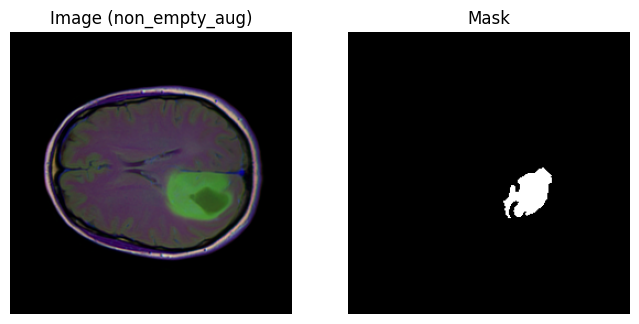

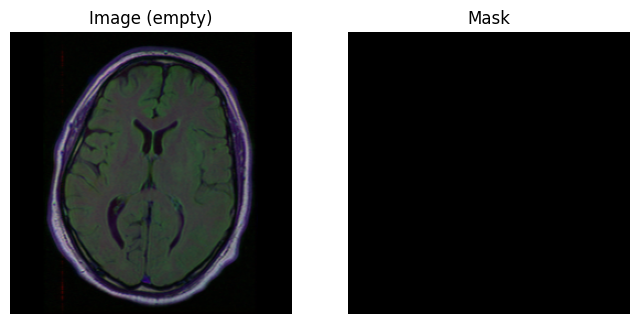

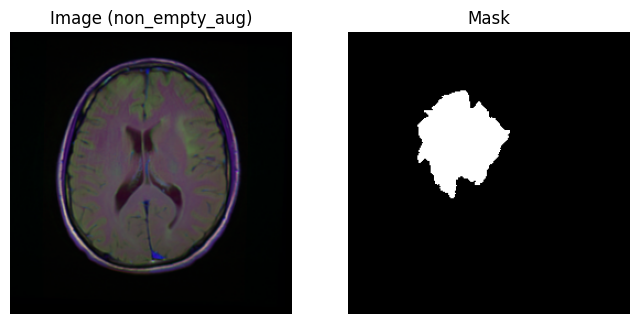

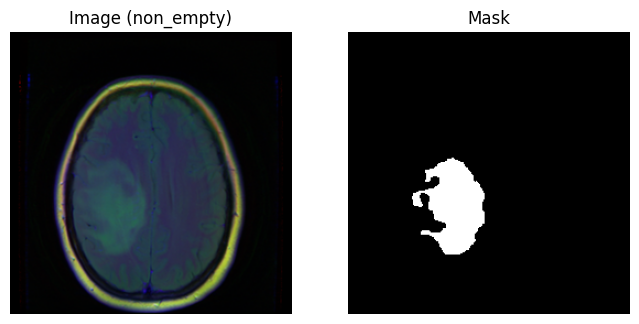

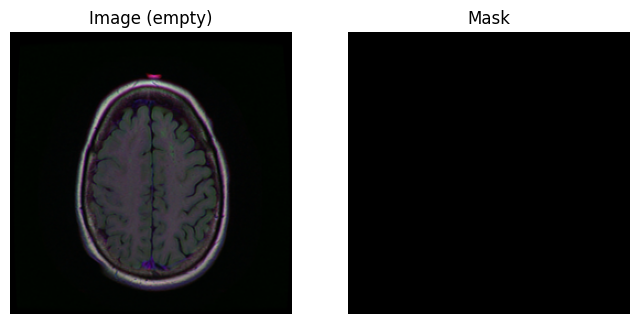

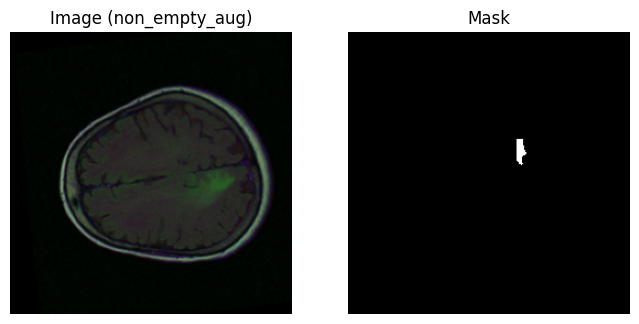

In [22]:
import random
import cv2
import matplotlib.pyplot as plt

# Load CSV
sample_df = train_balanced_df.sample(6, random_state=42).reset_index(drop=True)

for i in range(len(sample_df)):
    img_path = sample_df.loc[i, "image_path"]
    mask_path = sample_df.loc[i, "mask_path"]
    
    img = cv2.imread(img_path)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    
    if img is None or mask is None:
        print(f"Skipping broken sample: {img_path}")
        continue
    
    # Convert to RGB for display
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(8,4))
    plt.subplot(1,2,1)
    plt.imshow(img_rgb)
    plt.title(f"Image ({sample_df.loc[i,'mask_type']})")
    plt.axis('off')
    
    plt.subplot(1,2,2)
    plt.imshow(mask, cmap='gray')
    plt.title("Mask")
    plt.axis('off')
    
    plt.show()


In [23]:




import os
import cv2
import csv
import torch
import random
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import jaccard_score
from torchvision import transforms

IMG_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 50
LR = 1e-4
PATIENCE = 5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training on:", device)

# Paths (update if needed)
TRAIN_CSV = "/kaggle/working/data/train_balanced.csv"
VAL_CSV = "/kaggle/working/data/val.csv"
TEST_CSV = "/kaggle/working/data/test.csv"

OUTPUT_DIR = "/kaggle/working/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(f"{OUTPUT_DIR}/overlays", exist_ok=True)
os.makedirs(f"{OUTPUT_DIR}/masks", exist_ok=True)

# DATASET CLASS
class BrainDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "image_path"]
        mask_path = self.df.loc[idx, "mask_path"]

        # Handle both "_mask.tif" or same filename
        if not os.path.exists(mask_path):
            base = os.path.splitext(os.path.basename(img_path))[0]
            alt_mask = os.path.join(os.path.dirname(mask_path), f"{base}_mask.tif")
            if os.path.exists(alt_mask):
                mask_path = alt_mask

        image = cv2.imread(img_path)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        if image is None or mask is None:
            raise FileNotFoundError(f"Missing image/mask pair: {img_path} / {mask_path}")

        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))

        image = image / 255.0
        mask = (mask > 127).astype(np.float32)

        if self.transform:
            image = self.transform(image)

        image = torch.tensor(image).permute(2, 0, 1).float()
        mask = torch.tensor(mask).unsqueeze(0).float()

        return image, mask

# MODEL: UNET
class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()
        def CBR(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True)
            )

        self.enc1 = CBR(3, 64)
        self.enc2 = CBR(64, 128)
        self.enc3 = CBR(128, 256)
        self.enc4 = CBR(256, 512)

        self.pool = nn.MaxPool2d(2)
        self.bottleneck = CBR(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = CBR(1024, 512)
        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = CBR(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = CBR(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = CBR(128, 64)
        self.out_conv = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return torch.sigmoid(self.out_conv(d1))

# METRICS
def dice_coeff(pred, target, smooth=1e-6):
    pred = (pred > 0.5).float()
    intersection = (pred * target).sum()
    return (2. * intersection + smooth) / (pred.sum() + target.sum() + smooth)

def iou_score(pred, target, smooth=1e-6):
    pred = (pred > 0.5).float()
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum() - intersection
    return (intersection + smooth) / (union + smooth)


# DATA LOADERS
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)

train_dataset = BrainDataset(train_df)
val_dataset = BrainDataset(val_df)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)


# TRAINING SETUP
model = UNet().to(device)
optimizer = optim.Adam(model.parameters(), lr=LR)
criterion = nn.BCELoss()
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

best_val_loss = float("inf")
epochs_no_improve = 0
history = []

# TRAINING LOOP
for epoch in range(EPOCHS):
    model.train()
    train_loss, train_dice, train_iou = 0, 0, 0

    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_dice += dice_coeff(outputs, masks).item()
        train_iou += iou_score(outputs, masks).item()

    train_loss /= len(train_loader)
    train_dice /= len(train_loader)
    train_iou /= len(train_loader)

    # Validation
    model.eval()
    val_loss, val_dice, val_iou = 0, 0, 0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            val_loss += loss.item()
            val_dice += dice_coeff(outputs, masks).item()
            val_iou += iou_score(outputs, masks).item()

    val_loss /= len(val_loader)
    val_dice /= len(val_loader)
    val_iou /= len(val_loader)
    scheduler.step(val_loss)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Dice: {val_dice:.4f}")

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), f"{OUTPUT_DIR}/best_model.pth")
    else:
        epochs_no_improve += 1

    history.append([epoch+1, train_loss, val_loss, train_dice, val_dice, train_iou, val_iou])
    pd.DataFrame(history, columns=["Epoch","TrainLoss","ValLoss","TrainDice","ValDice","TrainIoU","ValIoU"]).to_csv(f"{OUTPUT_DIR}/train_history.csv", index=False)

    # Early stopping
    if epochs_no_improve >= PATIENCE:
        print("Early stopping triggered!")
        break

# Save final model
torch.save(model.state_dict(), f"{OUTPUT_DIR}/final_model.pth")

print("\nTraining completed! Best model saved as 'best_model.pth'")

# GENERATE PREDICTIONS & LABEL BOX CSV
model.load_state_dict(torch.load(f"{OUTPUT_DIR}/best_model.pth"))
model.eval()

label_rows = []
for idx, (images, masks) in enumerate(tqdm(val_loader, desc="Saving predictions")):
    images = images.to(device)
    preds = model(images)
    preds = (preds > 0.5).float().cpu().numpy()

    for i in range(len(preds)):
        pred_mask = preds[i,0]
        overlay = (images[i].cpu().permute(1,2,0).numpy()*255).astype(np.uint8)
        mask_vis = (pred_mask*255).astype(np.uint8)
        contours, _ = cv2.findContours(mask_vis, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        for cnt in contours:
            x,y,w,h = cv2.boundingRect(cnt)
            label_rows.append(["val", idx, x, y, w, h])

        # Save mask & overlay
        cv2.imwrite(f"{OUTPUT_DIR}/masks/pred_{idx}.png", mask_vis)
        overlay_mask = overlay.copy()
        overlay_mask[mask_vis>128] = [255,0,0]
        cv2.imwrite(f"{OUTPUT_DIR}/overlays/overlay_{idx}.png", overlay_mask)

pd.DataFrame(label_rows, columns=["Split","Index","x","y","w","h"]).to_csv(f"{OUTPUT_DIR}/label_boxes.csv", index=False)
print(" Predictions, overlays, and label boxes saved successfully.")


Training on: cuda


Epoch 1/50: 100%|██████████| 584/584 [04:31<00:00,  2.15it/s]


Epoch 1/50 | Train Loss: 0.2829 | Val Loss: 0.1658 | Val Dice: 0.0000


Epoch 2/50: 100%|██████████| 584/584 [04:31<00:00,  2.15it/s]


Epoch 2/50 | Train Loss: 0.1361 | Val Loss: 0.0874 | Val Dice: 0.0000


Epoch 3/50: 100%|██████████| 584/584 [04:31<00:00,  2.15it/s]


... (61 outputs left out)

Epoch 34/50: 100%|██████████| 584/584 [04:31<00:00,  2.15it/s]


Epoch 34/50 | Train Loss: 0.0387 | Val Loss: 0.0137 | Val Dice: 0.6442
Early stopping triggered!

Training completed! Best model saved as 'best_model.pth'


Saving predictions: 100%|██████████| 74/74 [00:15<00:00,  4.82it/s]

 Predictions, overlays, and label boxes saved successfully.


In [25]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# ========= CONFIG =========
IMG_SIZE = 256
BATCH_SIZE = 8
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TEST_CSV = "/kaggle/working/data/test.csv"
OUTPUT_DIR = "/kaggle/working/outputs"
MODEL_PATH = f"{OUTPUT_DIR}/best_model.pth"

os.makedirs(f"{OUTPUT_DIR}/test_preds", exist_ok=True)
os.makedirs(f"{OUTPUT_DIR}/test_overlays", exist_ok=True)

# ========= DATASET CLASS =========
class BrainDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "image_path"]
        mask_path = self.df.loc[idx, "mask_path"] if "mask_path" in self.df.columns else None

        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"Missing image: {img_path}")
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
        image = image / 255.0
        image = torch.tensor(image).permute(2, 0, 1).float()

        if mask_path and os.path.exists(mask_path):
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
            mask = (mask > 127).astype(np.float32)
            mask = torch.tensor(mask).unsqueeze(0).float()
            return image, mask
        else:
            return image, torch.zeros((1, IMG_SIZE, IMG_SIZE))

# ========= MODEL =========
class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()
        def CBR(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True)
            )

        self.enc1 = CBR(3, 64)
        self.enc2 = CBR(64, 128)
        self.enc3 = CBR(128, 256)
        self.enc4 = CBR(256, 512)

        self.pool = nn.MaxPool2d(2)
        self.bottleneck = CBR(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = CBR(1024, 512)
        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = CBR(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = CBR(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = CBR(128, 64)
        self.out_conv = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return torch.sigmoid(self.out_conv(d1))

# ========= METRICS =========
def dice_coeff(pred, target, smooth=1e-6):
    pred = (pred > 0.5).float()
    intersection = (pred * target).sum()
    return (2. * intersection + smooth) / (pred.sum() + target.sum() + smooth)

def iou_score(pred, target, smooth=1e-6):
    pred = (pred > 0.5).float()
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum() - intersection
    return (intersection + smooth) / (union + smooth)

# ========= LOAD MODEL =========
print(f"Loading model from {MODEL_PATH} ...")
model = UNet().to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

# ========= LOAD TEST DATA =========
test_df = pd.read_csv(TEST_CSV)
test_dataset = BrainDataset(test_df)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

# ========= INFERENCE =========
dice_scores, iou_scores = [], []
label_boxes = []

print("\nRunning inference on test set...")
for idx, (images, masks) in enumerate(tqdm(test_loader)):
    images, masks = images.to(DEVICE), masks.to(DEVICE)
    with torch.no_grad():
        preds = model(images)
    preds = (preds > 0.5).float()

    # Metrics
    dice = dice_coeff(preds, masks).item()
    iou = iou_score(preds, masks).item()
    dice_scores.append(dice)
    iou_scores.append(iou)

    # Convert to numpy for saving
    img_np = (images[0].cpu().permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    mask_np = (preds[0, 0].cpu().numpy() * 255).astype(np.uint8)

    # Save mask
    cv2.imwrite(f"{OUTPUT_DIR}/test_preds/pred_{idx}.png", mask_np)

    # Overlay visualization
    overlay = img_np.copy()
    overlay[mask_np > 128] = [255, 0, 0]
    cv2.imwrite(f"{OUTPUT_DIR}/test_overlays/overlay_{idx}.png", overlay)

    # Bounding boxes
    contours, _ = cv2.findContours(mask_np, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        label_boxes.append(["test", idx, x, y, w, h])

# ========= SAVE RESULTS =========
pd.DataFrame(label_boxes, columns=["Split", "Index", "x", "y", "w", "h"]).to_csv(
    f"{OUTPUT_DIR}/test_label_boxes.csv", index=False)

mean_dice = np.mean(dice_scores)
mean_iou = np.mean(iou_scores)

print(f"\n✅ Inference completed!")
print(f"Average Dice Coefficient: {mean_dice:.4f}")
print(f"Average IoU Score: {mean_iou:.4f}")
print(f"Results saved to: {OUTPUT_DIR}/test_preds, test_overlays, test_label_boxes.csv")


Loading model from /kaggle/working/outputs/best_model.pth ...

Running inference on test set...


100%|██████████| 590/590 [00:16<00:00, 36.44it/s]


✅ Inference completed!
Average Dice Coefficient: 0.8360
Average IoU Score: 0.8056
Results saved to: /kaggle/working/outputs/test_preds, test_overlays, test_label_boxes.csv


In [27]:
import os

for root, dirs, files in os.walk("/kaggle/working"):
    for f in files:
        if "best_model" in f:
            print(os.path.join(root, f))


/kaggle/working/outputs/best_model.pth


In [28]:
import torch
import torch.nn as nn

#UNet Architecture
class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()
        
        def CBR(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True)
            )

        self.enc1 = CBR(3, 64)
        self.enc2 = CBR(64, 128)
        self.enc3 = CBR(128, 256)
        self.enc4 = CBR(256, 512)

        self.pool = nn.MaxPool2d(2)
        self.bottleneck = CBR(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = CBR(1024, 512)
        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = CBR(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = CBR(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = CBR(128, 64)
        self.out_conv = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return torch.sigmoid(self.out_conv(d1))


#Load Model
MODEL_PATH = "/kaggle/working/outputs/best_model.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet().to(DEVICE)
state_dict = torch.load(MODEL_PATH, map_location=DEVICE)
model.load_state_dict(state_dict)
model.eval()

print("Model loaded successfully and ready for inference!")


Model loaded successfully and ready for inference!


In [30]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import os
from torchvision import transforms
from PIL import Image

#SANITY CHECK — MULTIPLE SAMPLE INFERENCE
def predict_image(img_path):
    img = Image.open(img_path).convert("L")
    transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor()
    ])
    tensor_img = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model(tensor_img)
        pred = pred.squeeze().cpu().numpy()

    return img, pred

# Replace these with a few test images you have
sample_images = [
    "/kaggle/working/data/test/image1.png",
    "/kaggle/working/data/test/image2.png"
]

for path in sample_images:
    if os.path.exists(path):
        img, mask = predict_image(path)
        print(f"Image: {path}")
        print("Mask stats:", mask.min(), mask.max(), mask.mean())
        plt.figure(figsize=(10,4))
        plt.subplot(1,2,1)
        plt.imshow(img, cmap="gray")
        plt.title("Original Image")
        plt.subplot(1,2,2)
        plt.imshow(mask > 0.5, cmap="gray")
        plt.title("Predicted Mask (thresholded)")
        plt.show()
    else:
        print(f" Skipping missing file: {path}")

print("\n Environment Summary:")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Model Parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")
print(" Sanity check complete. Model ready for deployment!")


 Skipping missing file: /kaggle/working/data/test/image1.png
 Skipping missing file: /kaggle/working/data/test/image2.png

 Environment Summary:
PyTorch Version: 2.6.0+cu124
CUDA available: True
Model Parameters: 31.04M
 Sanity check complete. Model ready for deployment!


In [31]:
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(DEVICE)
model.eval()

with torch.no_grad():
    sample = test_dataset[0][0].unsqueeze(0).to(DEVICE)  # move to same device
    pred = model(sample)
    print(pred.shape, pred.min().item(), pred.max().item())


torch.Size([1, 1, 256, 256]) 3.5482628391036997e-08 0.6888101696968079


In [32]:
import os

base_dir = "/kaggle/working/data"
for root, dirs, files in os.walk(base_dir):
    print(root, "->", len(files), "files")


/kaggle/working/data -> 3 files
/kaggle/working/data/masks -> 3929 files
/kaggle/working/data/augmented -> 0 files
/kaggle/working/data/augmented/masks -> 1922 files
/kaggle/working/data/augmented/images -> 1922 files
/kaggle/working/data/images -> 3929 files


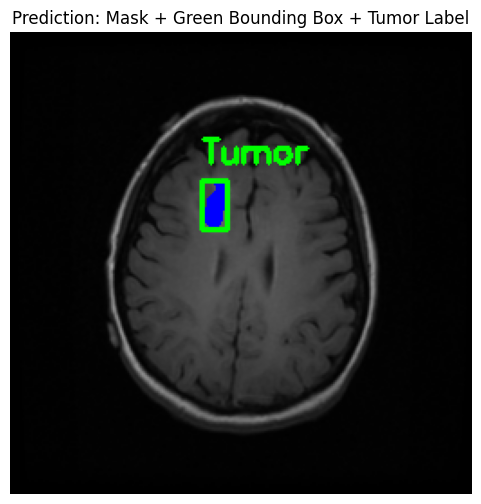

In [60]:
import os
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Rectangle

#CONFIG
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMG_SIZE = 256
MODEL_PATH = "/kaggle/working/outputs/best_model.pth"
VAL_CSV = "/kaggle/working/data/val.csv"
OUTPUT_DIR = "/kaggle/working/outputs"

#LOAD MODEL
class UNet(torch.nn.Module):
    def __init__(self):
        super(UNet, self).__init__()
        def CBR(in_ch, out_ch):
            return torch.nn.Sequential(
                torch.nn.Conv2d(in_ch, out_ch, 3, padding=1),
                torch.nn.BatchNorm2d(out_ch),
                torch.nn.ReLU(inplace=True),
                torch.nn.Conv2d(out_ch, out_ch, 3, padding=1),
                torch.nn.BatchNorm2d(out_ch),
                torch.nn.ReLU(inplace=True)
            )
        self.enc1 = CBR(3, 64)
        self.enc2 = CBR(64, 128)
        self.enc3 = CBR(128, 256)
        self.enc4 = CBR(256, 512)
        self.pool = torch.nn.MaxPool2d(2)
        self.bottleneck = CBR(512, 1024)
        self.up4 = torch.nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = CBR(1024, 512)
        self.up3 = torch.nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = CBR(512, 256)
        self.up2 = torch.nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = CBR(256, 128)
        self.up1 = torch.nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = CBR(128, 64)
        self.out_conv = torch.nn.Conv2d(64, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return torch.sigmoid(self.out_conv(d1))

# Load model
model = UNet().to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

#LOAD ONE SAMPLE
val_df = pd.read_csv(VAL_CSV)
sample = val_df.sample(1).iloc[0]
img_path = sample["image_path"]
mask_path = sample["mask_path"]

image = cv2.imread(img_path)
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

# Resize & normalize
image_resized = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
input_tensor = torch.tensor(image_resized / 255.0).permute(2, 0, 1).unsqueeze(0).float().to(DEVICE)

#PREDICTION
with torch.no_grad():
    pred = model(input_tensor)
pred_mask = (pred[0, 0].cpu().numpy() > 0.5).astype(np.uint8) * 255

#FIND BOUNDING BOX
contours, _ = cv2.findContours(pred_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
bbox = None
if len(contours) > 0:
    c = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(c)
    bbox = (x, y, w, h)

#VISUALIZATION
gray_img = cv2.cvtColor(image_resized, cv2.COLOR_BGR2GRAY)
colored_img = cv2.cvtColor(gray_img, cv2.COLOR_GRAY2RGB)

# Overlay red mask
overlay = colored_img.copy()
overlay[pred_mask > 128] = [255, 0, 0]  # red tumor

# Add bounding box and label
if bbox:
    x, y, w, h = bbox
    cv2.rectangle(overlay, (x, y), (x + w, y + h), (0, 255, 0), 2)  # green box
    cv2.putText(overlay, "Tumor", (x, y - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

# ======== DISPLAY ========
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Prediction: Mask + Green Bounding Box + Tumor Label")
plt.show()


In [66]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# ========= PATHS =========
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_PATH = "/kaggle/working/outputs/best_model.pth"
VAL_CSV = "/kaggle/working/data/val.csv"   # ✅ update only if path differs

IMG_SIZE = 256
BATCH_SIZE = 8

# ========= DATASET =========
class BrainDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "image_path"]
        mask_path = self.df.loc[idx, "mask_path"]

        image = cv2.imread(img_path)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE)) / 255.0
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
        mask = (mask > 127).astype(np.float32)

        image = torch.tensor(image).permute(2, 0, 1).float()
        mask = torch.tensor(mask).unsqueeze(0).float()
        return image, mask

# ========= UNET (your original version) =========
class UNet(torch.nn.Module):
    def __init__(self):
        super(UNet, self).__init__()
        def CBR(in_ch, out_ch):
            return torch.nn.Sequential(
                torch.nn.Conv2d(in_ch, out_ch, 3, padding=1),
                torch.nn.BatchNorm2d(out_ch),
                torch.nn.ReLU(inplace=True),
                torch.nn.Conv2d(out_ch, out_ch, 3, padding=1),
                torch.nn.BatchNorm2d(out_ch),
                torch.nn.ReLU(inplace=True)
            )

        self.enc1 = CBR(3, 64)
        self.enc2 = CBR(64, 128)
        self.enc3 = CBR(128, 256)
        self.enc4 = CBR(256, 512)
        self.pool = torch.nn.MaxPool2d(2)
        self.bottleneck = CBR(512, 1024)

        self.up4 = torch.nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = CBR(1024, 512)
        self.up3 = torch.nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = CBR(512, 256)
        self.up2 = torch.nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = CBR(256, 128)
        self.up1 = torch.nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = CBR(128, 64)
        self.out_conv = torch.nn.Conv2d(64, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return torch.sigmoid(self.out_conv(d1))

# ========= METRIC FUNCTIONS =========
def dice_coeff(pred, target, smooth=1e-6):
    pred = (pred > 0.5).float()
    intersection = (pred * target).sum()
    return (2. * intersection + smooth) / (pred.sum() + target.sum() + smooth)

def iou_score(pred, target, smooth=1e-6):
    pred = (pred > 0.5).float()
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum() - intersection
    return (intersection + smooth) / (union + smooth)

# ========= LOAD MODEL =========
model = UNet().to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

# ========= LOAD VALIDATION DATA =========
val_df = pd.read_csv(VAL_CSV)
val_dataset = BrainDataset(val_df)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# ========= EVALUATION =========
dice_total, iou_total = 0, 0
y_true, y_pred = [], []

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Evaluating best model"):
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        outputs = model(images)
        preds = (outputs > 0.5).float()

        dice_total += dice_coeff(preds, masks).item()
        iou_total += iou_score(preds, masks).item()

        # Flatten for classification metrics
        y_true.extend(masks.cpu().numpy().flatten())
        y_pred.extend(preds.cpu().numpy().flatten())

# ========= METRIC CALCULATION =========
y_true = np.array(y_true)
y_pred = np.array(y_pred)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
dice = dice_total / len(val_loader)
iou = iou_total / len(val_loader)

print("\n===== MODEL PERFORMANCE (Best Saved Model) =====")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"Dice Coeff: {dice:.4f}")
print(f"IoU Score : {iou:.4f}")
print("===============================================")


Evaluating best model: 100%|██████████| 74/74 [00:18<00:00,  4.09it/s]



===== MODEL PERFORMANCE (Best Saved Model) =====
Accuracy : 0.9960
Precision: 0.8989
Recall   : 0.7145
F1 Score : 0.7961
Dice Coeff: 0.6963
IoU Score : 0.5783


In [68]:
!ls /kaggle/working/
!ls /kaggle/working/outputs
!ls /kaggle/working/data


data  outputs
best_model.pth	 masks		       test_overlays	  visuals
final_model.pth  overlays	       test_preds
label_boxes.csv  test_label_boxes.csv  train_history.csv
augmented  images  masks  test.csv  train_balanced.csv	val.csv


In [69]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from tqdm import tqdm
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

#FIXED PATHS
TRAIN_CSV = "/kaggle/working/data/train_balanced.csv"
VAL_CSV   = "/kaggle/working/data/val.csv"
MODEL_PATH = "/kaggle/working/outputs/best_model.pth"
OUTPUT_DIR = "/kaggle/working/outputs"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

#LOAD DATA
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)

train_dataset = BrainDataset(train_df)
val_dataset   = BrainDataset(val_df)
train_loader  = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2)
val_loader    = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2)

print(f"Train samples: {len(train_dataset)} | Val samples: {len(val_dataset)}")

#LOAD MODEL
model = UNet().to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
print("Loaded pretrained weights from best_model.pth")

#FINE-TUNING SETUP
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-5)  # smaller LR for fine-tuning
EPOCHS = 5

#TRAINING LOOP (Fine-tuning)
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for images, masks in tqdm(train_loader, desc=f"Fine-tuning Epoch {epoch+1}/{EPOCHS}"):
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1}: Fine-tuning Loss = {running_loss/len(train_loader):.4f}")

#SAVE UPDATED MODEL
torch.save(model.state_dict(), f"{OUTPUT_DIR}/fine_tuned_model.pth")
print("Fine-tuned model saved as fine_tuned_model.pth")

#EVALUATE ON VALIDATION SET
model.eval()
all_preds, all_targets = [], []

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Evaluating"):
        images, masks = images.to(device), masks.to(device)
        outputs = model(images)
        preds = (outputs > 0.5).float()
        all_preds.extend(preds.cpu().numpy().flatten())
        all_targets.extend(masks.cpu().numpy().flatten())

#COMPUTE METRICS
acc = accuracy_score(all_targets, all_preds)
prec = precision_score(all_targets, all_preds, zero_division=0)
rec = recall_score(all_targets, all_preds, zero_division=0)
f1 = f1_score(all_targets, all_preds, zero_division=0)

# Dice & IoU
def dice_coeff(pred, target, smooth=1e-6):
    pred = torch.tensor(pred)
    target = torch.tensor(target)
    intersection = (pred * target).sum()
    return (2. * intersection + smooth) / (pred.sum() + target.sum() + smooth)

def iou_score(pred, target, smooth=1e-6):
    pred = torch.tensor(pred)
    target = torch.tensor(target)
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum() - intersection
    return (intersection + smooth) / (union + smooth)

dice = dice_coeff(all_preds, all_targets).item()
iou  = iou_score(all_preds, all_targets).item()

print("\nMODEL PERFORMANCE (Fine-tuned)")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"Dice Coeff: {dice:.4f}")
print(f"IoU Score : {iou:.4f}")



Device: cuda
Train samples: 4672 | Val samples: 589
Loaded pretrained weights from best_model.pth


Fine-tuning Epoch 1/5: 100%|██████████| 584/584 [04:30<00:00,  2.16it/s]


Epoch 1: Fine-tuning Loss = 0.0433


Fine-tuning Epoch 2/5: 100%|██████████| 584/584 [04:31<00:00,  2.15it/s]


Epoch 2: Fine-tuning Loss = 0.0419


Fine-tuning Epoch 3/5: 100%|██████████| 584/584 [04:31<00:00,  2.15it/s]


... (3 outputs left out)

Fine-tuning Epoch 5/5: 100%|██████████| 584/584 [04:31<00:00,  2.15it/s]


Epoch 5: Fine-tuning Loss = 0.0396
✅ Fine-tuned model saved as fine_tuned_model.pth


Evaluating: 100%|██████████| 74/74 [00:19<00:00,  3.87it/s]



===== MODEL PERFORMANCE (Fine-tuned) =====
Accuracy : 0.9960
Precision: 0.8709
Recall   : 0.7442
F1 Score : 0.8026
Dice Coeff: 0.8026
IoU Score : 0.6703


In [84]:
import os
import cv2
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import gradio as gr
from tqdm import tqdm

#PATHS & SETTINGS
MODEL_PATH = "outputs/best_model.pth"
IMG_SIZE = 256
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMAGE_FOLDER = "images"  # folder for batch inference
OUTPUT_DIR = "outputs"
MASKS_DIR = os.path.join(OUTPUT_DIR, "masks")
OVERLAYS_DIR = os.path.join(OUTPUT_DIR, "overlays")
os.makedirs(MASKS_DIR, exist_ok=True)
os.makedirs(OVERLAYS_DIR, exist_ok=True)

#UNet DEFINITION
class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()
        def CBR(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True)
            )

        self.enc1 = CBR(3, 64)
        self.enc2 = CBR(64, 128)
        self.enc3 = CBR(128, 256)
        self.enc4 = CBR(256, 512)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = CBR(512, 1024)
        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = CBR(1024, 512)
        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = CBR(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = CBR(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = CBR(128, 64)
        self.out_conv = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return torch.sigmoid(self.out_conv(d1))

#LOAD MODEL
model = UNet().to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

#PREPROCESS
def preprocess(image: np.ndarray):
    orig_size = image.shape[:2]  # H, W
    image_resized = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
    image_resized = image_resized / 255.0
    image_resized = np.transpose(image_resized, (2,0,1))  # HWC -> CHW
    tensor = torch.tensor(image_resized, dtype=torch.float32).unsqueeze(0).to(DEVICE)
    return tensor, orig_size

#POSTPROCESS
def postprocess(mask_tensor, orig_size):
    mask = mask_tensor.squeeze().cpu().detach().numpy()
    mask = (mask > 0.5).astype(np.uint8) * 255
    mask = cv2.resize(mask, (orig_size[1], orig_size[0]))
    return mask

#OVERLAY WITH RED TUMOR
def overlay_mask(image: np.ndarray, mask: np.ndarray, alpha=0.5):
    color_mask = np.zeros_like(image)
    color_mask[:, :, 2] = mask  # red channel
    overlay = cv2.addWeighted(image, 1-alpha, color_mask, alpha, 0)
    return overlay

#SINGLE IMAGE INFERENCE
def segment_brain(image: np.ndarray, alpha: float = 0.5):
    tensor, orig_size = preprocess(image)
    with torch.no_grad():
        output = model(tensor)
    mask = postprocess(output, orig_size)
    overlay = overlay_mask(image, mask, alpha=alpha)
    
    # Save outputs
    mask_filename = os.path.join(MASKS_DIR, "mask.png")
    overlay_filename = os.path.join(OVERLAYS_DIR, "overlay.png")
    cv2.imwrite(mask_filename, mask)
    cv2.imwrite(overlay_filename, overlay)
    
    # Bounding boxes CSV
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    rows = []
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        rows.append(["uploaded_image", x, y, w, h])
    df = pd.DataFrame(rows, columns=["Image","x","y","w","h"])
    df.to_csv(os.path.join(OUTPUT_DIR, "uploaded_label_boxes.csv"), index=False)
    
    return Image.fromarray(mask), Image.fromarray(overlay)

#BATCH INFERENCE
def batch_inference(folder=IMAGE_FOLDER, alpha: float = 0.5):
    label_rows = []
    for filename in tqdm(os.listdir(folder)):
        filepath = os.path.join(folder, filename)
        image = cv2.imread(filepath)
        if image is None:
            continue
        tensor, orig_size = preprocess(image)
        with torch.no_grad():
            output = model(tensor)
        mask = postprocess(output, orig_size)
        overlay = overlay_mask(image, mask, alpha=alpha)
        
        # Save mask and overlay
        cv2.imwrite(os.path.join(MASKS_DIR, f"mask_{filename}"), mask)
        cv2.imwrite(os.path.join(OVERLAYS_DIR, f"overlay_{filename}"), overlay)
        
        # Bounding boxes
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for cnt in contours:
            x, y, w, h = cv2.boundingRect(cnt)
            label_rows.append([filename, x, y, w, h])
    
    df = pd.DataFrame(label_rows, columns=["Image","x","y","w","h"])
    df.to_csv(os.path.join(OUTPUT_DIR, "batch_label_boxes.csv"), index=False)
    print(f"Batch inference completed! Results saved in {OUTPUT_DIR}")

# ===== GRADIO INTERFACE =====
iface = gr.Interface(
    fn=segment_brain,
    inputs=[gr.Image(type="numpy", label="Upload MRI Image"),
            gr.Slider(0,1,0.5, step=0.05, label="Overlay Transparency")],
    outputs=[gr.Image(type="pil", label="Segmentation Mask"),
             gr.Image(type="pil", label="Overlay")],
    title="Brain Tumor Segmentation",
    description="Upload an MRI image to get the segmented mask, overlay, and bounding boxes CSV.",
    flagging_mode="never"
)

if __name__ == "__main__":
    print("Launching interactive Gradio app...")
    iface.launch()


Launching interactive Gradio app...
* Running on local URL:  http://127.0.0.1:7862
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

* Running on public URL: https://01a18b372b30e7e406.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [89]:
import os
import shutil

#Paths
DEPLOY_DIR = "/kaggle/working/brain_segmentation"
MODEL_SRC = "/kaggle/working/outputs/best_model.pth"

#Create folder
os.makedirs(DEPLOY_DIR, exist_ok=True)
print(f" Folder created at {DEPLOY_DIR}")

#Copy model
shutil.copy(MODEL_SRC, DEPLOY_DIR)
print(f" Model copied to {DEPLOY_DIR}")

#Write app.py
app_code = """
import os
import cv2
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import gradio as gr

MODEL_PATH = "best_model.pth"
IMG_SIZE = 256
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()
        def CBR(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, 3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True)
            )
        self.enc1 = CBR(3, 64)
        self.enc2 = CBR(64, 128)
        self.enc3 = CBR(128, 256)
        self.enc4 = CBR(256, 512)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = CBR(512, 1024)
        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = CBR(1024, 512)
        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = CBR(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = CBR(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = CBR(128, 64)
        self.out_conv = nn.Conv2d(64, 1, 1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return torch.sigmoid(self.out_conv(d1))

# Load model
model = UNet().to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

# Preprocess & postprocess
def preprocess(image: np.ndarray):
    orig_size = image.shape[:2]
    image_resized = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
    image_resized = image_resized / 255.0
    image_resized = np.transpose(image_resized, (2,0,1))
    tensor = torch.tensor(image_resized, dtype=torch.float32).unsqueeze(0).to(DEVICE)
    return tensor, orig_size

def postprocess(mask_tensor, orig_size):
    mask = mask_tensor.squeeze().cpu().detach().numpy()
    mask = (mask > 0.5).astype(np.uint8) * 255
    mask = cv2.resize(mask, (orig_size[1], orig_size[0]))
    return mask

def overlay_mask(image: np.ndarray, mask: np.ndarray, alpha=0.5):
    color_mask = np.zeros_like(image)
    color_mask[:, :, 1] = mask
    overlay = cv2.addWeighted(image, 1-alpha, color_mask, alpha, 0)
    return overlay

def segment_brain(image: np.ndarray):
    tensor, orig_size = preprocess(image)
    with torch.no_grad():
        output = model(tensor)
    mask = postprocess(output, orig_size)
    overlay = overlay_mask(image, mask)
    return Image.fromarray(mask), Image.fromarray(overlay)

iface = gr.Interface(
    fn=segment_brain,
    inputs=gr.Image(type="numpy"),
    outputs=[gr.Image(type="pil", label="Mask"),
             gr.Image(type="pil", label="Overlay")],
    title="Brain Tumor Segmentation",
    description="Upload an MRI image to get segmented mask and overlay.",
    allow_flagging="never"
)

if __name__ == "__main__":
    iface.launch()
"""

with open(os.path.join(DEPLOY_DIR, "app.py"), "w") as f:
    f.write(app_code)
print(" app.py created")

#Create requirements.txt
requirements = """torch
torchvision
numpy
opencv-python
pandas
gradio
Pillow
tqdm
"""

with open(os.path.join(DEPLOY_DIR, "requirements.txt"), "w") as f:
    f.write(requirements)
print("requirements.txt created")

#List folder contents
print("Deployment folder contents:", os.listdir(DEPLOY_DIR))


 Folder created at /kaggle/working/brain_segmentation
 Model copied to /kaggle/working/brain_segmentation
 app.py created
requirements.txt created
Deployment folder contents: ['app.py', 'best_model.pth', 'requirements.txt']


In [90]:
shutil.make_archive("/kaggle/working/brain_segmentation", 'zip', "/kaggle/working/brain_segmentation")


'/kaggle/working/brain_segmentation.zip'

In [92]:
import shutil
import os

# Source folder containing your deployment files
src_folder = "/kaggle/working/brain_segmentation"

# Destination zip path
zip_path = "/kaggle/working/brain_segmentation.zip"

# Create zip
shutil.make_archive(base_name=zip_path.replace(".zip",""), format='zip', root_dir=src_folder)
print(f"Deployment folder zipped at {zip_path}")


✅ Deployment folder zipped at /kaggle/working/brain_segmentation.zip
